# Módulo 53: Modelos de regresión

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m53-modelos-de-regresion.ipynb](m53-modelos-de-regresion.ipynb). No es una tarea entregada del programa.

Ajustar una regresión es solo el primer paso. Un modelo útil también debe elegir bien sus variables, cuantificar la incertidumbre de sus predicciones y cumplir los supuestos que justifican sus pruebas. En esta lección se recorre ese ciclo completo con los datos de inversión publicitaria y ventas de `advertising.csv`:

1. Regresión múltiple e interpretación de coeficientes
2. Eliminación hacia atrás
3. Intervalo de confianza frente a intervalo de predicción
4. Los supuestos LINE
5. Normalidad: prueba de Jarque–Bera
6. Homocedasticidad: prueba de White
7. Independencia: estadístico de Durbin–Watson
8. Multicolinealidad: VIF
9. Errores frecuentes
10. Ejercicio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from statsmodels.stats.diagnostic import het_white
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 1. Regresión múltiple e interpretación de coeficientes

`advertising.csv` tiene 200 mercados con el presupuesto invertido en TV, radio y periódico, y las ventas obtenidas. Se reserva el 30 % para prueba.

En una regresión múltiple, $\hat\beta_j$ es el cambio esperado en las ventas por cada unidad adicional de presupuesto en el medio $j$, **manteniendo fijos los demás medios**. Es un efecto parcial, no la relación simple entre dos columnas.

In [2]:
publicidad = pd.read_csv("advertising.csv")
entrenamiento, prueba = train_test_split(publicidad, test_size=0.3, random_state=42)

medios = ["TV", "Radio", "Newspaper"]
completo = sm.OLS(entrenamiento["Sales"], sm.add_constant(entrenamiento[medios])).fit()
print(completo.params.round(4))
print("\nCorrelaciones con Sales:")
print(publicidad.corr()["Sales"].drop("Sales").round(3))

const        4.7438
TV           0.0536
Radio        0.1027
Newspaper    0.0079
dtype: float64

Correlaciones con Sales:
TV           0.901
Radio        0.350
Newspaper    0.158
Name: Sales, dtype: float64


Por sí solo, el periódico tiene una correlación positiva con las ventas, pero en el modelo múltiple su coeficiente es casi nulo. La razón es que el periódico está correlacionado con la radio (0.35 en todos los datos): una vez que se conoce la inversión en radio, el periódico no añade información.

## 2. Eliminación hacia atrás

La **eliminación hacia atrás** parte del modelo con todos los predictores y, en cada paso, quita el de mayor p-valor si supera $\alpha$. Se detiene cuando todos los que quedan son significativos. La constante nunca se elimina.

In [3]:
def eliminacion_atras(datos, respuesta, predictores, alpha=0.05):
    actuales = list(predictores)
    while actuales:
        modelo = sm.OLS(datos[respuesta], sm.add_constant(datos[actuales])).fit()
        pvalores = modelo.pvalues.drop("const")
        peor = pvalores.idxmax()
        if pvalores[peor] <= alpha:
            break
        print(f"Se elimina {peor} (p = {pvalores[peor]:.3f})")
        actuales.remove(peor)
    return actuales

seleccion = eliminacion_atras(entrenamiento, "Sales", medios)
modelo = sm.OLS(entrenamiento["Sales"], sm.add_constant(entrenamiento[seleccion])).fit()
print("Predictores finales:", seleccion)
print(modelo.params.round(4))

Se elimina Newspaper (p = 0.289)
Predictores finales: ['TV', 'Radio']
const    4.8921
TV       0.0536
Radio    0.1065
dtype: float64


Con la radio fija, cada unidad adicional de presupuesto en TV se asocia con unas 0.054 unidades más de ventas; con la TV fija, cada unidad en radio, con unas 0.11.

## 3. Intervalo de confianza frente a intervalo de predicción

Para un punto nuevo $x_0$ (con el 1 de la constante), la predicción es $\hat y_0 = x_0^\top\hat\beta$. Hay dos preguntas distintas:

- **¿Cuáles son las ventas promedio** de todos los mercados con ese presupuesto? Intervalo de confianza de la media:

$$\hat y_0 \pm t_{1-\alpha/2,\; n-p-1}\; \hat\sigma \sqrt{x_0^\top (X^\top X)^{-1} x_0}.$$

- **¿Cuánto venderá un mercado concreto** con ese presupuesto? Intervalo de predicción, que suma la variabilidad propia de cada observación, el "1+":

$$\hat y_0 \pm t_{1-\alpha/2,\; n-p-1}\; \hat\sigma \sqrt{1 + x_0^\top (X^\top X)^{-1} x_0}.$$

El intervalo de predicción siempre es más ancho, y no se estrecha a 0 aunque haya muchos datos. En `statsmodels`, `get_prediction(x0).summary_frame(alpha=...)` devuelve los dos:

| Columnas | Intervalo |
| --- | --- |
| `mean_ci_lower`, `mean_ci_upper` | Confianza para la media |
| `obs_ci_lower`, `obs_ci_upper` | Predicción para una observación nueva |

In [4]:
nuevo = pd.DataFrame({"const": [1.0], "TV": [150.0], "Radio": [25.0]})
marco = modelo.get_prediction(nuevo).summary_frame(alpha=0.10)      # intervalos al 90 %
print(marco.round(3))

# Cálculo a mano
X = sm.add_constant(entrenamiento[seleccion]).to_numpy()
x0 = nuevo.to_numpy()[0]
h = x0 @ np.linalg.inv(X.T @ X) @ x0
sigma = np.sqrt(modelo.scale)                      # scale = SS_res / (n - p - 1)
t_crit = stats.t.ppf(0.95, df=modelo.df_resid)
y0 = x0 @ modelo.params.to_numpy()
print(f"\nIC media a mano:      [{y0 - t_crit * sigma * np.sqrt(h):.3f}, {y0 + t_crit * sigma * np.sqrt(h):.3f}]")
print(f"IP observación a mano: [{y0 - t_crit * sigma * np.sqrt(1 + h):.3f}, {y0 + t_crit * sigma * np.sqrt(1 + h):.3f}]")

     mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  15.597    0.146         15.355         15.838        12.754         18.44

IC media a mano:      [15.355, 15.838]
IP observación a mano: [12.754, 18.440]


Con datos de prueba se comprueba qué significa cada uno: alrededor del 90 % de las ventas reales deberían caer dentro de su intervalo de predicción al 90 %, mientras que el intervalo de la media, mucho más estrecho, deja fuera a la mayoría.

In [5]:
marco_te = modelo.get_prediction(sm.add_constant(prueba[seleccion])).summary_frame(alpha=0.10)
y_te = prueba["Sales"].to_numpy()
dentro_ip = ((y_te >= marco_te["obs_ci_lower"]) & (y_te <= marco_te["obs_ci_upper"])).mean()
dentro_ic = ((y_te >= marco_te["mean_ci_lower"]) & (y_te <= marco_te["mean_ci_upper"])).mean()
print(f"Ventas de prueba dentro del intervalo de predicción: {dentro_ip:.1%}")
print(f"Ventas de prueba dentro del intervalo de la media:   {dentro_ic:.1%}")

Ventas de prueba dentro del intervalo de predicción: 93.3%
Ventas de prueba dentro del intervalo de la media:   33.3%


## 4. Los supuestos LINE

Las pruebas t y F, y los intervalos, se apoyan en cuatro supuestos sobre los errores:

| Letra | Supuesto | Diagnóstico |
| --- | --- | --- |
| **L** | Linealidad: la media de $y$ es lineal en los predictores | Gráfica de residuos contra ajustados |
| **I** | Independencia de los errores | Durbin–Watson (si hay un orden) |
| **N** | Normalidad de los errores | Jarque–Bera, gráfica Q-Q |
| **E** | Igualdad de varianzas (homocedasticidad) | White, Breusch–Pagan |

A ellos se suma una condición sobre los predictores: que no haya multicolinealidad fuerte.

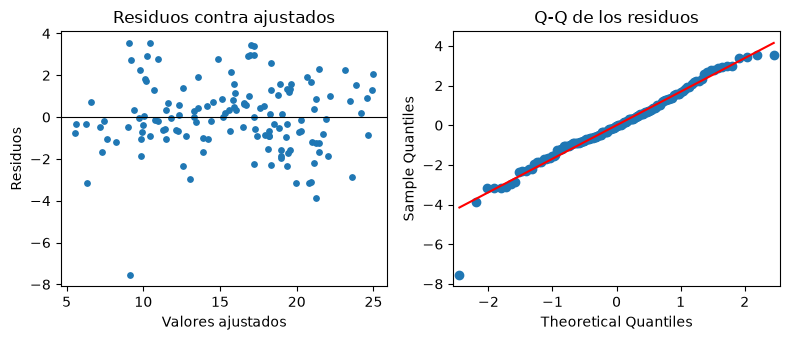

In [6]:
residuos = modelo.resid
ajustados = modelo.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].scatter(ajustados, residuos, s=15)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xlabel("Valores ajustados")
axes[0].set_ylabel("Residuos")
axes[0].set_title("Residuos contra ajustados")
sm.qqplot(residuos, line="s", ax=axes[1])
axes[1].set_title("Q-Q de los residuos")
plt.tight_layout()
plt.show()

Los residuos se reparten alrededor de 0 sin una forma clara, salvo un residuo atípico cercano a −7.5. En la gráfica Q-Q ese punto y la cola izquierda se separan de la recta: es la asimetría negativa que detecta la prueba de Jarque–Bera en la sección siguiente.

## 5. Normalidad: prueba de Jarque–Bera

Una distribución normal tiene asimetría $S = 0$ y curtosis $K = 3$. Jarque–Bera mide cuánto se alejan de esos valores los residuos:

$$JB = \frac{n}{6}\left(S^2 + \frac{(K - 3)^2}{4}\right) \sim \chi^2_2 \text{ bajo } H_0: \text{los errores son normales}.$$

In [7]:
S = stats.skew(residuos)
K = stats.kurtosis(residuos, fisher=False)        # fisher=False: la normal tiene K = 3
n = len(residuos)
JB = n / 6 * (S ** 2 + (K - 3) ** 2 / 4)
print(f"S = {S:.3f}, K = {K:.3f}")
print(f"JB a mano: {JB:.3f}, p = {stats.chi2.sf(JB, 2):.4f}")
jb, p_jb, _, _ = jarque_bera(residuos)
print(f"statsmodels: {jb:.3f}, p = {p_jb:.4f}")

S = -0.479, K = 4.885
JB a mano: 26.073, p = 0.0000
statsmodels: 26.073, p = 0.0000


## 6. Homocedasticidad: prueba de White

La prueba de White regresa los residuos al cuadrado $e_i^2$ sobre los predictores, sus cuadrados y sus productos cruzados. Si los errores tienen varianza constante, esa regresión auxiliar no debería explicar nada:

$$LM = n\, R^2_{aux} \sim \chi^2_q \text{ bajo } H_0: \text{homocedasticidad},$$

con $q$ el número de regresores auxiliares sin contar la constante. `het_white` recibe los residuos y la matriz de diseño **con** constante.

In [8]:
lm, p_lm, _, _ = het_white(residuos, modelo.model.exog)

# Regresión auxiliar a mano: TV, Radio, TV², TV·Radio, Radio²
tv, radio = entrenamiento["TV"], entrenamiento["Radio"]
aux = sm.add_constant(pd.DataFrame({"TV": tv, "Radio": radio, "TV2": tv ** 2,
                                    "TVxRadio": tv * radio, "Radio2": radio ** 2}))
r2_aux = sm.OLS(residuos ** 2, aux).fit().rsquared
print(f"LM a mano: {n * r2_aux:.3f}, p = {stats.chi2.sf(n * r2_aux, 5):.4f}")
print(f"het_white: {lm:.3f}, p = {p_lm:.4f}")

LM a mano: 7.527, p = 0.1843
het_white: 7.527, p = 0.1843


## 7. Independencia: estadístico de Durbin–Watson

Durbin–Watson mide la correlación entre residuos consecutivos:

$$DW = \frac{\sum_{t=2}^{n} (e_t - e_{t-1})^2}{\sum_{t=1}^{n} e_t^2} \approx 2(1 - \hat\rho_1),$$

donde $\hat\rho_1$ es la autocorrelación de orden 1. Vale cerca de 2 sin autocorrelación, cerca de 0 con autocorrelación positiva y cerca de 4 con negativa. Solo tiene sentido cuando las filas siguen un orden natural, como el tiempo; aquí se calculan en el orden original del archivo.

In [9]:
e = residuos.sort_index().to_numpy()               # orden original de las filas
dw = np.sum(np.diff(e) ** 2) / np.sum(e ** 2)
rho1 = np.corrcoef(e[:-1], e[1:])[0, 1]
print(f"DW a mano: {dw:.3f}   statsmodels: {durbin_watson(e):.3f}")
print(f"2(1 - ρ1) = {2 * (1 - rho1):.3f}")

DW a mano: 2.351   statsmodels: 2.351
2(1 - ρ1) = 2.353


## 8. Multicolinealidad: VIF

El **factor de inflación de la varianza** del predictor $j$ se obtiene regresando $x_j$ sobre los demás predictores (con constante) y usando su $R_j^2$:

$$VIF_j = \frac{1}{1 - R_j^2}.$$

Indica cuántas veces se infla la varianza de $\hat\beta_j$ por la correlación con los demás. Valores mayores que 5 o 10 suelen considerarse problemáticos. `variance_inflation_factor` hace esa regresión con las demás columnas de la matriz que recibe, así que hay que pasarle la matriz **con la constante** y omitir después la fila de la constante.

In [10]:
X_vif = sm.add_constant(entrenamiento[medios])
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
                index=X_vif.columns).drop("const")
print("VIF (con constante):")
print(vif.round(3))

# A mano para Newspaper: regresión sobre TV y Radio, con constante
r2_j = sm.OLS(entrenamiento["Newspaper"], sm.add_constant(entrenamiento[["TV", "Radio"]])).fit().rsquared
print(f"VIF de Newspaper a mano: {1 / (1 - r2_j):.3f}")

VIF (con constante):
TV           1.004
Radio        1.136
Newspaper    1.132
dtype: float64
VIF de Newspaper a mano: 1.132


## 9. Errores frecuentes

**Calcular el VIF sin constante.** Sin la columna de unos, la regresión auxiliar no centra los datos y su $R^2$ mide también la media de cada variable. Los VIF salen inflados aunque las variables casi no estén correlacionadas:

In [11]:
X_sin_const = entrenamiento[medios]
vif_mal = pd.Series([variance_inflation_factor(X_sin_const.values, i) for i in range(3)], index=medios)
print(pd.DataFrame({"sin constante (mal)": vif_mal, "con constante": vif}).round(3))

           sin constante (mal)  con constante
TV                       2.698          1.004
Radio                    3.474          1.136
Newspaper                3.163          1.132


**Reportar el intervalo de la media como si fuera de predicción.** `get_prediction(x0).conf_int()` devuelve el intervalo de la **media**. Para el rango en que caerá un valor concreto hay que usar las columnas `obs_ci_*` de `summary_frame`. Como se vio en la sección 3, el intervalo de la media deja fuera a la mayoría de las observaciones nuevas.

**Interpretar un coeficiente como si los demás no existieran.** El coeficiente de un predictor depende de qué otros predictores hay en el modelo; quitar o añadir uno correlacionado lo cambia.

**Ignorar una prueba de White que rechaza.** Si hay heterocedasticidad, los coeficientes siguen siendo insesgados, pero los errores estándar habituales no son fiables. Una solución es usar errores estándar robustos:

In [12]:
robusto = sm.OLS(entrenamiento["Sales"], sm.add_constant(entrenamiento[seleccion])).fit(cov_type="HC3")
print(pd.DataFrame({"SE clásico": modelo.bse, "SE robusto HC3": robusto.bse}).round(4))

       SE clásico  SE robusto HC3
const      0.3750          0.3987
TV         0.0017          0.0021
Radio      0.0099          0.0108


## 10. Ejercicio

Una heladería registra sus ventas diarias durante 300 días:

```python
rng = np.random.default_rng(42)
n = 300
helados = pd.DataFrame({
    "temperatura": rng.uniform(15, 38, n),
    "precio": rng.uniform(20, 40, n),
    "promocion": rng.integers(0, 2, n),
    "humedad": rng.uniform(30, 90, n),
})
helados["ventas"] = (50 + 6 * helados["temperatura"] - 2.5 * helados["precio"]
                     + 25 * helados["promocion"]
                     + rng.normal(0, 1, n) * 0.6 * helados["temperatura"])
```

1. Divide en entrenamiento (70 %) y prueba y aplica la eliminación hacia atrás con las cuatro variables.
2. Para un día de 30 °C, precio 25, con promoción y humedad 60, calcula el intervalo de confianza de la media y el de predicción al 95 %.
3. Aplica las pruebas de Jarque–Bera y White, y calcula Durbin–Watson.
4. Calcula el VIF con constante de los predictores finales.
5. Si White rechaza, compara los errores estándar clásicos con los robustos HC3.

### Solución

In [13]:
rng = np.random.default_rng(42)
n_h = 300
helados = pd.DataFrame({
    "temperatura": rng.uniform(15, 38, n_h),
    "precio": rng.uniform(20, 40, n_h),
    "promocion": rng.integers(0, 2, n_h),
    "humedad": rng.uniform(30, 90, n_h),
})
helados["ventas"] = (50 + 6 * helados["temperatura"] - 2.5 * helados["precio"]
                     + 25 * helados["promocion"]
                     + rng.normal(0, 1, n_h) * 0.6 * helados["temperatura"])

# 1. Eliminación hacia atrás
h_tr, h_te = train_test_split(helados, test_size=0.3, random_state=42)
finales = eliminacion_atras(h_tr, "ventas", ["temperatura", "precio", "promocion", "humedad"])
m_h = sm.OLS(h_tr["ventas"], sm.add_constant(h_tr[finales])).fit()
print("Predictores finales:", finales)

# 2. Intervalos para el día nuevo
dia = pd.DataFrame({"temperatura": [30.0], "precio": [25.0], "promocion": [1], "humedad": [60.0]})
x_dia = sm.add_constant(dia[finales], has_constant="add")
print(m_h.get_prediction(x_dia).summary_frame(alpha=0.05)
      [["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]].round(2))

Se elimina humedad (p = 0.606)
Predictores finales: ['temperatura', 'precio', 'promocion']
     mean  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  195.14         191.28         198.99        162.93        227.35


In [14]:
# 3. Supuestos
_, p_jb_h, _, _ = jarque_bera(m_h.resid)
_, p_white_h, _, _ = het_white(m_h.resid, m_h.model.exog)
print(f"Jarque-Bera p = {p_jb_h:.4f} | White p = {p_white_h:.4f} | DW = {durbin_watson(m_h.resid.sort_index()):.3f}")

# 4. VIF con constante
Xh = sm.add_constant(h_tr[finales])
print(pd.Series([variance_inflation_factor(Xh.values, i) for i in range(Xh.shape[1])],
                index=Xh.columns).drop("const").round(3))

# 5. Errores estándar robustos
m_h_rob = sm.OLS(h_tr["ventas"], Xh).fit(cov_type="HC3")
print(pd.DataFrame({"clásico": m_h.bse, "HC3": m_h_rob.bse}).round(3))

Jarque-Bera p = 0.0254 | White p = 0.0001 | DW = 1.902
temperatura    1.017
precio         1.005
promocion      1.018
dtype: float64
             clásico    HC3
const          7.365  7.687
temperatura    0.170  0.177
precio         0.196  0.213
promocion      2.263  2.286


La humedad no influye en las ventas simuladas y la eliminación hacia atrás la descarta. White rechaza la homocedasticidad, como se esperaba: el ruido crece con la temperatura. Jarque–Bera también rechaza al 5 %, porque mezclar errores de varianzas distintas engorda las colas. Los errores estándar robustos salen algo mayores que los clásicos. Los VIF son cercanos a 1 porque los predictores se generaron de forma independiente.

## Resumen

- En regresión múltiple cada coeficiente es un efecto parcial: el cambio en $y$ con los demás predictores fijos.
- La eliminación hacia atrás quita, uno a uno, los predictores con mayor p-valor, sin tocar la constante.
- El intervalo de confianza de la media usa $\sqrt{x_0^\top(X^\top X)^{-1}x_0}$; el de predicción añade el "1+" y es el que cubre observaciones nuevas (`obs_ci_*`).
- Los supuestos LINE se revisan con gráficas de residuos y con las pruebas de Jarque–Bera (normalidad), White (homocedasticidad) y Durbin–Watson (independencia).
- El VIF, $1/(1 - R_j^2)$, se calcula con constante; si hay heterocedasticidad, los errores estándar robustos corrigen la inferencia.

En el **Módulo 54** se empieza a trabajar con series de tiempo, donde el orden de las observaciones sí importa.